In [1]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cartopy.io.img_tiles as cimgt
import matplotlib.colors as mcolors
import matplotlib.cm as cm
from matplotlib.colors import LogNorm, Normalize
import proplot as plot
import rioxarray
import xarray as xr
import numpy as np
from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER
import warnings
import geopandas as gpd
plot.rc['cmap.discrete'] = False
import os
warnings.filterwarnings("ignore")

ERROR 1: PROJ: proj_create_from_database: Open of /home/alessandrom/anaconda3/envs/bias_correction_conda/share/proj failed
/home/alessandrom/anaconda3/envs/bias_correction_conda/lib/python3.10/site-packages/gribapi/__init__.py:23: UserWarning: ecCodes 2.31.0 or higher is recommended. You are running version 2.16.0
  warnings.warn(


In [2]:
country = 'croatia'

In [3]:
geom_path = f'../world_map/ne_50m_admin_0_countries.shp'
geometries = gpd.read_file(geom_path)
geometries = geometries[geometries['NAME_EN'] == f'{country.capitalize()}']['geometry']

In [4]:
month= 1

months_names = ['January','February','March','April','May','June','July',
                'August','September','October','November','December']

in_path   = f'../data/atlas_data/{country}/ssrd_integrated_{country}_m{month}.nc'
xdf = xr.open_mfdataset(in_path)

In [5]:
#Annual Plot: Opening all the monthly files and concatenate them in a single file.

#files_list = []
#for month in range(1,13):
    #in_path   = f'../data/atlas_data/ssrd_integrated_{country}_m{month}.nc'
#    month_file = xr.open_mfdataset(in_path).assign(month=month)
#    files_list.append(month_file)
#xdf_all = xr.concat(files_list,dim='month')

# Annual average - also a seasonal mean can be performed. 
#xdf = xdf_all.mean('month')

In [6]:
# EXCLUDING THE OROGRAPHY FROM THE PLOT
orog = xr.open_dataset(f'../DEMdata/{country}/glo90_orography_{country}.nc')
mask = orog['z'] > 2000

xdf = xdf.where(~mask, drop=False)

In [7]:
import cartopy.io.img_tiles as cimgt

class StadiaStamen(cimgt.Stamen):
    def _image_url(self, tile):
         x,y,z = tile
         url = f"https://tiles.stadiamaps.com/tiles/stamen_terrain_background/{z}/{x}/{y}.png?api_key=16f26ea8-2565-4da3-972a-49888d65b1e8"
         return url
        
class StadiaMap(cimgt.GoogleTiles):
    def __init__(self, style='alidade_smooth'):
        self._style = style
        super().__init__()

    def _image_url(self, tile):
        x, y, z = tile
        url = f"https://tiles.stadiamaps.com/tiles/{self._style}/{z}/{x}/{y}.png?api_key=16f26ea8-2565-4da3-972a-49888d65b1e8"
        return url

In [8]:
def draw_map(xdf, vmin, vmax, legend=False, label=None, title=None, suptitle=None, orient='vertical'):

    fig, ax = plot.subplots(ncols=1, figsize=(10, 7), subplot_kw={'projection': ccrs.PlateCarree()})

    # Create a Stamen terrain background map
    #stamen_terrain = StadiaStamen("terrain-background")
    stadia_terrain = StadiaMap("stamen_terrain_background")
    
    #ax.add_image(stadia_terrain, 6)
    
    ax.add_feature(cfeature.LAKES, edgecolor='black', facecolor='light blue')
    ax.add_feature(cfeature.OCEAN, edgecolor='light blue')
    ax.add_feature(cfeature.RIVERS, edgecolor='light blue')
    ax.add_feature(cfeature.COASTLINE, edgecolor='black', linewidth=1.2)
    ax.add_feature(cfeature.BORDERS, edgecolor='black', linewidth=1.2)

    xdf.rio.set_spatial_dims(x_dim="longitude", y_dim="latitude", inplace=True)
    xdf.rio.write_crs("epsg:4326", inplace=True)

    #xdf = xdf.rio.clip(geometries)
    
    cbar_kwargs = {
        'orientation': 'vertical',
        'shrink': 0.25,
        'aspect': 50,
        'pad': 0.2,
        'label': label,
        'labelsize': 11,
        
    } if legend else None

    im = xdf.plot.pcolormesh(ax = ax, transform=ccrs.PlateCarree(),
                        #norm=LogNorm(),
                        vmin=vmin, vmax=vmax,
                        cmap='Fire',
                        add_colorbar=legend, 
                        add_labels=False, 
                        cbar_kwargs=cbar_kwargs
                       )

    if orient == 'horizontal':
        cbar = im.colorbar
        cbar.ax.tick_params(axis='y', rotation=90)
    
    # Add longitude-latitude grid
    gl = ax.gridlines(draw_labels=True, linewidth=0.5, color='gray', alpha=0.5, linestyle='--')
    gl.xlabels_top = False
    gl.ylabels_right = False
    gl.xformatter = LONGITUDE_FORMATTER
    gl.yformatter = LATITUDE_FORMATTER

    lat_min =  np.min(xdf.latitude.values) -1
    lat_max =  np.max(xdf.latitude.values) +1
    lon_min =  np.min(xdf.longitude.values)-1
    lon_max = np.max(xdf.longitude.values) +1

    ax.set_extent([lon_min, lon_max, lat_min, lat_max], crs=ccrs.PlateCarree())
    ax.set_title(title, fontsize=14)
    fig.suptitle(suptitle, fontsize=17)
    return fig

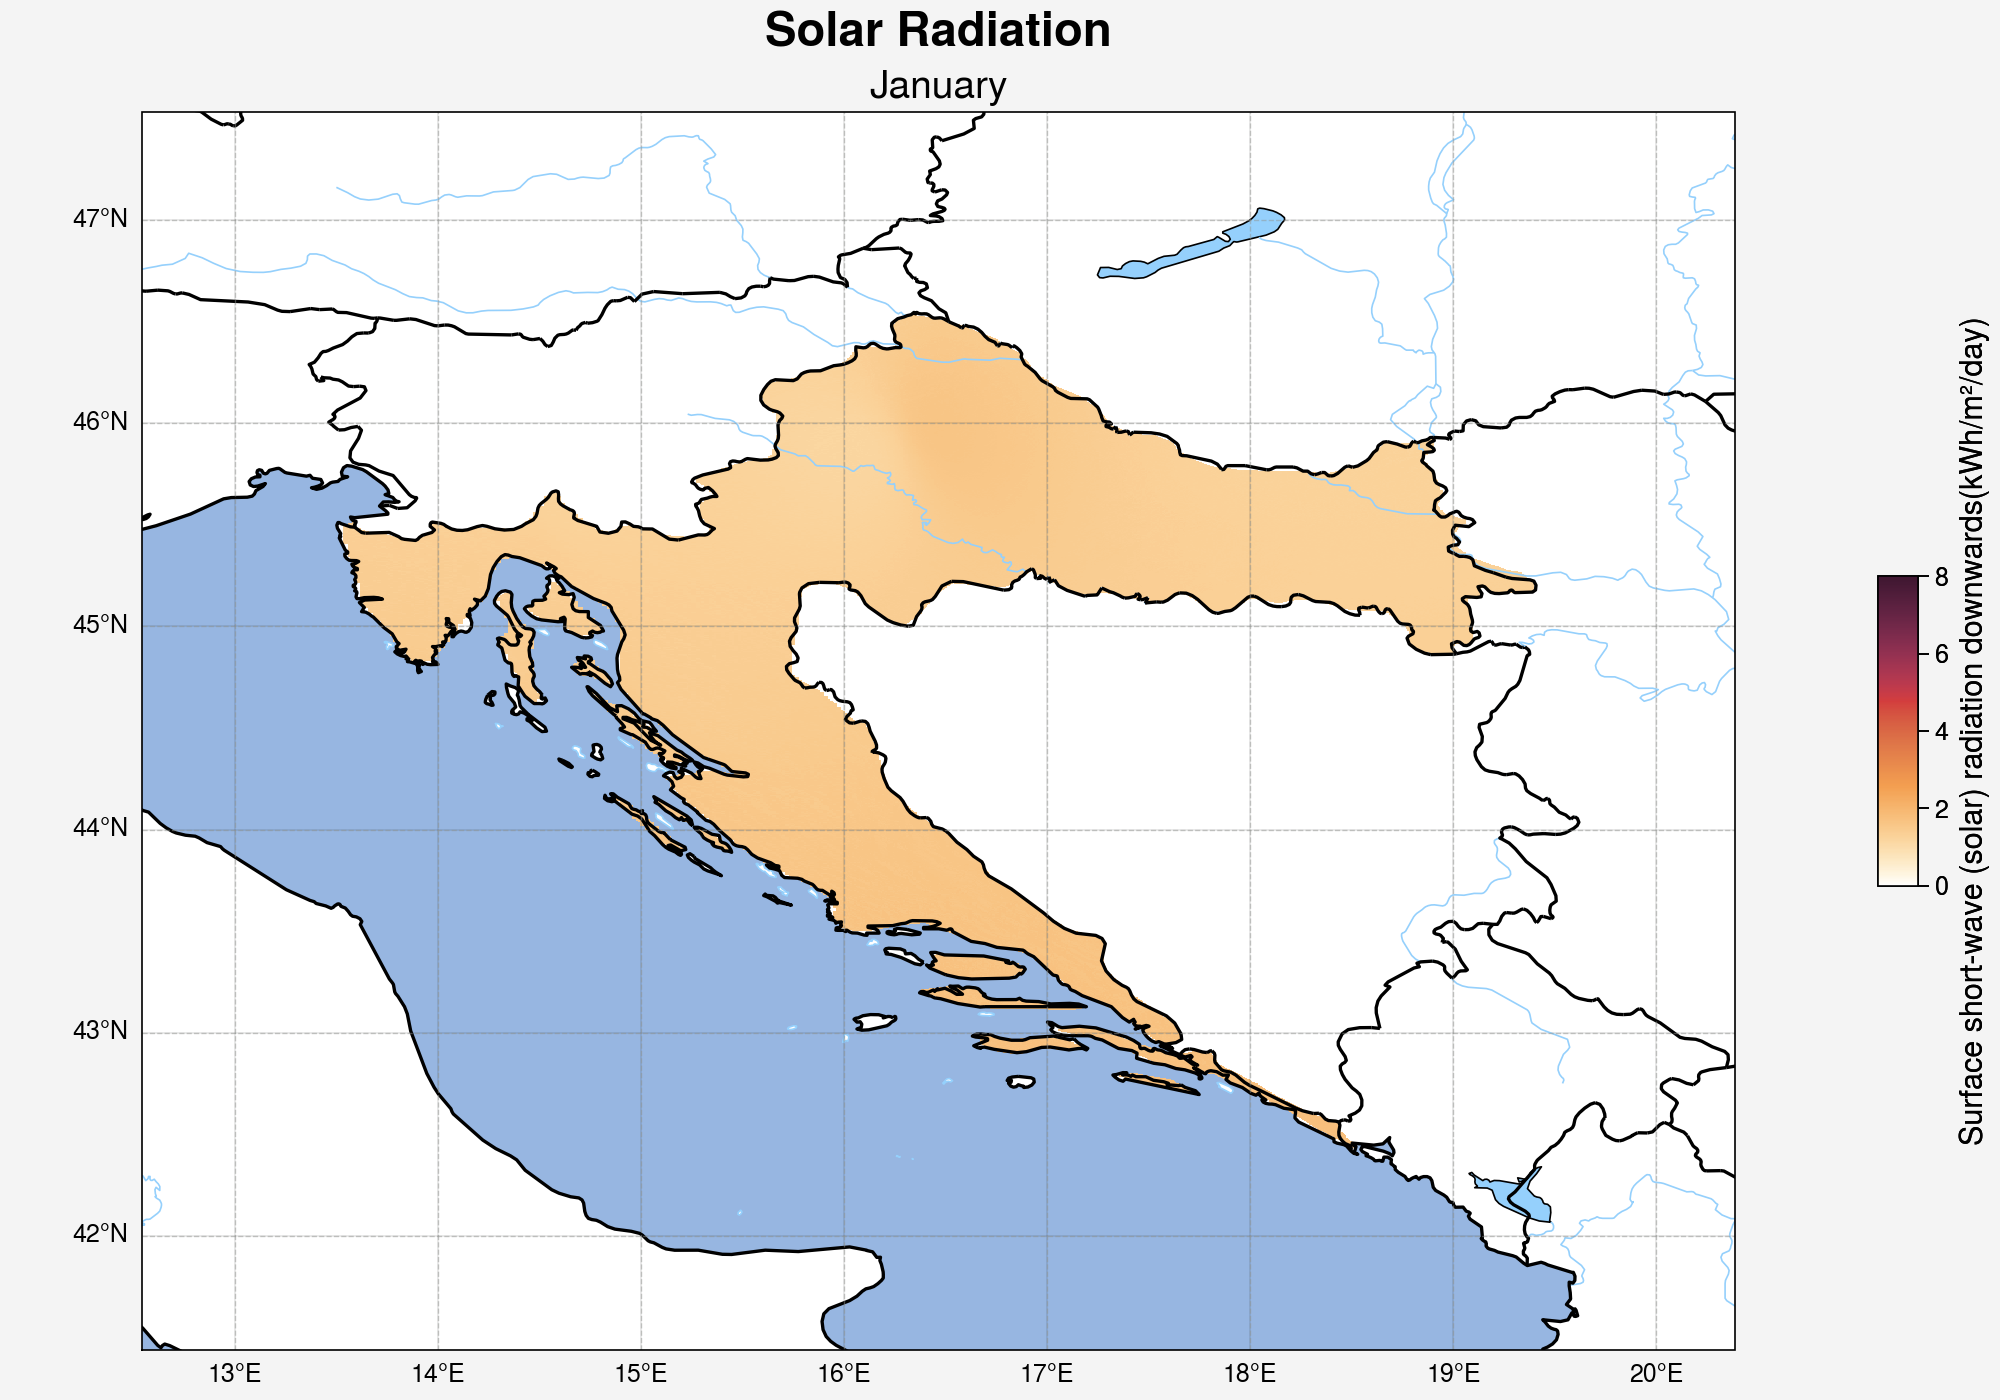

In [10]:
fig = draw_map(xdf['ssrd_integrated'],
               0, 8, True, 'Surface short-wave (solar) radiation downwards(kWh/m²/day)',
               months_names[month-1], #Set 'Annual' for the annual plot.
               'Solar Radiation')
output_path = f'../data/figures/{country}/'
output_dir = os.path.dirname(output_path)
os.makedirs(output_dir, exist_ok=True)
fig.save(f'{output_path}INTEGRATED_rd_{country}_overall_solar_era5land_m{month}.png')